# Generating CIFAR-10 images with a rectified flow

This notebook trains a generative model of small colour images (CIFAR-10, 32 x 32 pixels) with
**rectified flow**, and then draws new images from it. It is the Python version of the C++ demo
`examples/demo_cnn_rectified.cu`, with the same network and training settings, so the two can be
compared directly (section 7).

**Rectified flow** in one paragraph. Take a noise image `x0` (Gaussian pixels) and a real image
`x1`, and the straight line between them, `x_t = (1 - t) x0 + t x1` for `t` from 0 to 1. Along that
line the velocity is `x1 - x0`. A network `v(x_t, t)` is trained to predict that velocity from the
point and the time alone. To generate an image, start from fresh noise and follow the predicted
velocity from `t = 0` to `t = 1` in small steps (Euler's method).

The network is a convolutional **UNet**. The `juzhen` package has `Sequential` networks, layers
applied one after another; a UNet also has skip connections, so here it is built from several
`Sequential` pieces joined in Python. That is the main thing this notebook shows beyond the
tutorial (`tutorial.ipynb`), which is a good place to start if you are new to `juzhen`.

You need a GPU build of `juzhen` (the CPU works but is very slow), matplotlib, and the CIFAR-10
binary data in `datasets/CIFAR10/cifar-10-batches-bin` of the repository:

```
curl -L https://www.cs.toronto.edu/~kriz/cifar-10-binary.tar.gz -o datasets/CIFAR10/cifar-10-binary.tar.gz
tar -xzf datasets/CIFAR10/cifar-10-binary.tar.gz -C datasets/CIFAR10
```

## 1. Settings

In [1]:
import math
import os
import time

import numpy as np
import matplotlib.pyplot as plt

import juzhen as jz

device = "gpu" if jz.has_gpu() else "cpu"
print("GPU backend:", jz.backend(), "| device:", device)

CIFAR_DIR = "../../datasets/CIFAR10/cifar-10-batches-bin"   # relative to this notebook
EPOCHS = 20          # per epoch: 8 s on an RTX 4090, 4.5 min on an AMD gfx1151, 13 min on an Apple M2
BATCH = 128          # images per step; the convolution layers are built for this batch size
WIDTH = 64           # channels of the first UNet level (then 2x and 4x)
LR = 2e-4            # peak learning rate of the cosine schedule
EULER_STEPS = 100    # steps of the ODE solver when generating
EMA_DECAY = 0.9999   # images are drawn with an exponential moving average of the weights
SEED = 42

jz.manual_seed(SEED)
rng = np.random.default_rng(SEED)

GPU backend: cuda | device: gpu


## 2. The data

Each CIFAR-10 file holds 10,000 records of one label byte and 3,072 pixel bytes (the red, green
and blue planes of a 32 x 32 image). The labels are not needed. Pixels are scaled to [-1, 1],
and each image becomes one row of 3,072 values, the channel-by-channel layout the convolution
layers expect.

In [2]:
def load_cifar10(folder):
    batches = []
    for k in range(1, 6):
        records = np.fromfile(os.path.join(folder, f"data_batch_{k}.bin"), dtype=np.uint8)
        batches.append(records.reshape(10000, 3073)[:, 1:])      # drop the label byte
    return np.concatenate(batches).astype(np.float32) / 127.5 - 1

images = load_cifar10(CIFAR_DIR)
print(images.shape, images.min(), images.max())

(50000, 3072) -1.0 1.0


A helper to show rows of 3,072 values as a grid of pictures. It takes numpy arrays or juzhen
matrices: `np.asarray` copies a matrix out of juzhen, from the GPU if it is there.

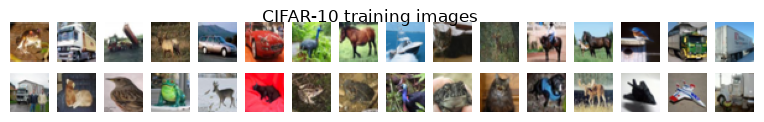

In [3]:
def show_images(rows, columns=16, title=None, scale=0.6):
    rows = np.asarray(rows)[:columns * ((len(rows) + columns - 1) // columns)]
    pictures = ((rows.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1) + 1) / 2).clip(0, 1)
    n_rows = (len(pictures) + columns - 1) // columns
    fig, axes = plt.subplots(n_rows, columns, figsize=(columns * scale, n_rows * scale))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, picture in zip(np.ravel(axes), pictures):
        ax.imshow(picture)
    if title:
        fig.suptitle(title)
    plt.show()

show_images(images[:32], title="CIFAR-10 training images")

## 3. Telling the network the time

The velocity depends on `t`, so the network needs it as an input. As in the C++ demo, `t` goes
in as extra image channels: for four frequencies `f`, one channel filled with `sin(f t)` and one
with `cos(f t)`. These eight channels are put next to the three colour channels, so the
network's input has 11 channels.

`t` is a column of `BATCH` values; `@ ones_plane` repeats each value over the 1,024 pixels of a
channel, and `jz.hstack` puts the channels side by side. All of it runs on the device.

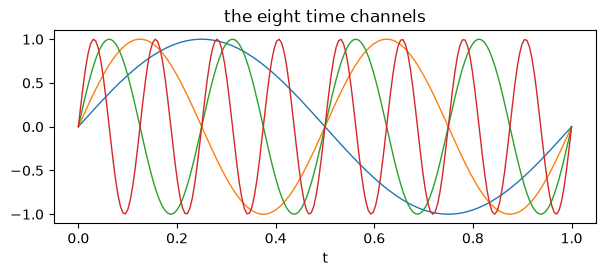

In [4]:
FREQUENCIES = [2 * math.pi * k for k in (1, 2, 4, 8)]
TIME_CHANNELS = 2 * len(FREQUENCIES)
ones_plane = jz.ones(1, 32 * 32, device=device)

def time_channels(t):
    planes = []
    for f in FREQUENCIES:
        planes += [jz.sin(t * f) @ ones_plane, jz.cos(t * f) @ ones_plane]
    return jz.hstack(planes)                     # BATCH x (8 * 1024)

t_demo = jz.array(np.linspace(0, 1, 200), device=device)
plt.figure(figsize=(7, 2.5))
plt.plot(np.linspace(0, 1, 200), time_channels(t_demo)[:, ::2 * 1024], lw=1)  # the first pixel of each channel
plt.xlabel("t")
plt.title("the eight time channels")
plt.show()

## 4. A UNet from `Sequential` pieces

The network, for `WIDTH = 64` (sizes are channels x height x width):

| piece | layers | output |
|---|---|---|
| `enc1`, `res_e1` | 3 x 3 convolution, residual block | 64 x 32 x 32 |
| `enc2`, `res_e2` | stride-2 convolution, residual block | 128 x 16 x 16 |
| `enc3_mid`, `res_mid` | stride-2 convolution, convolution, residual block | 256 x 8 x 8 |
| `up2`, `dec2`, `res_d2` | 4 x 4 transposed convolution, **joined with `res_e2`'s output**, convolution, residual block | 128 x 16 x 16 |
| `up1`, `dec1`, `res_d1` | transposed convolution, **joined with `res_e1`'s output**, convolution, residual block | 64 x 32 x 32 |
| `head` | 3 x 3 convolution without ReLU | 3 x 32 x 32 |

Every convolution but the last is followed by a ReLU. Each piece is a `jz.Sequential`; Python
joins them. Two things are not a plain chain of layers:

* **Skip connections** (in bold): the decoder sees the upsampled features *and* the encoder's
  features from the same level, side by side (`jz.hstack`). In the backward pass the gradient of
  the joined input is split by columns: the first part goes back through the upsampling, the
  second back to the encoder, where it is added to the gradient arriving through the bottleneck.
* **Residual blocks** compute `x + b(relu(a(x)))`. Their backward pass is
  `body.backward(g) + g`. The weights of `b` start at zero, so a new block passes `x` through.

Calling a `Sequential` keeps its input for `backward`; `predict` does not, for generating.

In [5]:
def conv(c_in, c_out, size, stride=1, relu=True):
    return jz.nn.Conv2d(c_in, c_out, 3, image_size=size, batch_size=BATCH, padding=1,
                        stride=stride, relu=relu)

def up(c_in, c_out, size):                       # doubles the height and width
    return jz.nn.ConvTranspose2d(c_in, c_out, 4, image_size=size, batch_size=BATCH, padding=1, stride=2)

def piece(*layers):
    return jz.Sequential(*layers, device=device)


class ResBlock:
    """x + b(relu(a(x))), where b starts at zero."""

    def __init__(self, channels, size):
        self.body = piece(conv(channels, channels, size), conv(channels, channels, size, relu=False))
        for p in self.body.parameters():
            if p.name == "layer1.weight":
                p.assign(jz.zeros(*p.shape, device=device))

    def __call__(self, x):
        return x + self.body(x)

    def predict(self, x):
        return x + self.body.predict(x)

    def backward(self, g):
        return self.body.backward(g) + g


class UNet:
    def __init__(self, width):
        c1, c2, c3 = width, 2 * width, 4 * width
        self.skip1, self.skip2 = c1 * 32 * 32, c2 * 16 * 16    # features of the two skip connections
        self.enc1 = piece(conv(3 + TIME_CHANNELS, c1, 32))
        self.res_e1 = ResBlock(c1, 32)
        self.enc2 = piece(conv(c1, c2, 32, stride=2))
        self.res_e2 = ResBlock(c2, 16)
        self.enc3_mid = piece(conv(c2, c3, 16, stride=2), conv(c3, c3, 8))
        self.res_mid = ResBlock(c3, 8)
        self.up2 = piece(up(c3, c2, 8))
        self.dec2 = piece(conv(2 * c2, c2, 16))
        self.res_d2 = ResBlock(c2, 16)
        self.up1 = piece(up(c2, c1, 16))
        self.dec1 = piece(conv(2 * c1, c1, 32))
        self.res_d1 = ResBlock(c1, 32)
        self.head = piece(conv(c1, 3, 32, relu=False))
        self.pieces = [self.enc1, self.res_e1.body, self.enc2, self.res_e2.body, self.enc3_mid,
                       self.res_mid.body, self.up2, self.dec2, self.res_d2.body, self.up1,
                       self.dec1, self.res_d1.body, self.head]

    def __call__(self, x, t, train=True):
        run = (lambda f, v: f(v)) if train else (lambda f, v: f.predict(v))
        inputs = jz.hstack([x, time_channels(t)])
        e1 = run(self.res_e1, run(self.enc1, inputs))
        e2 = run(self.res_e2, run(self.enc2, e1))
        m = run(self.res_mid, run(self.enc3_mid, e2))
        d2 = run(self.res_d2, run(self.dec2, jz.hstack([run(self.up2, m), e2])))
        d1 = run(self.res_d1, run(self.dec1, jz.hstack([run(self.up1, d2), e1])))
        return run(self.head, d1)

    def backward(self, g):
        """g: the gradient of the loss with respect to the output of the last call."""
        g_cat1 = self.dec1.backward(self.res_d1.backward(self.head.backward(g)))
        g_cat2 = self.dec2.backward(self.res_d2.backward(self.up1.backward(g_cat1[:, :self.skip1])))
        g_e2 = self.enc3_mid.backward(self.res_mid.backward(self.up2.backward(g_cat2[:, :self.skip2])))
        g_e2 += g_cat2[:, self.skip2:]           # the skip connection's share
        g_e1 = self.enc2.backward(self.res_e2.backward(g_e2))
        g_e1 += g_cat1[:, self.skip1:]
        self.enc1.backward(self.res_e1.backward(g_e1))

    def parameters(self):
        return [p for s in self.pieces for p in s.parameters()]


net = UNet(WIDTH)
print(f"{len(net.pieces)} pieces, {sum(int(np.prod(p.shape)) for p in net.parameters()):,} parameters")

13 pieces, 3,909,827 parameters


## 5. Training

Each step takes a batch of real images `x1` (half of them mirrored left to right), noise `x0`
and times `t` uniform on [0, 1], and trains the network to predict `x1 - x0` at
`x_t = (1 - t) x0 + t x1` with the squared error (`jz.nn.mse`).

* **Optimizers.** AdamW updates each parameter on its own, so one optimizer per piece gives the
  same updates as one for the whole network.
* **Learning rate.** Warm up over the first 5% of the steps, then a cosine decay to 1% of `LR`.
* **Weight average (EMA).** After each step, `average = d * average + (1 - d) * weights`.
  Images drawn with the averaged weights are much cleaner than with the last weights.

Like the C++ demo, the loop reads the loss every step, which makes it wait for the GPU each time;
that keeps the speed comparison fair.

In [6]:
optimizers = [jz.optim.AdamW(s.parameters(), lr=LR, weight_decay=0) for s in net.pieces]


class WeightAverage:
    def __init__(self, params, decay):
        self.params, self.decay = params, decay
        self.average = [p.value for p in params]       # .value is a copy

    def update(self, step):
        d = min(self.decay, (1 + step) / (10 + step))  # a short warm-up
        for p, a in zip(self.params, self.average):
            a *= d
            a += p.value * (1 - d)

    def swap(self):
        """Exchange the network's weights and the averaged ones."""
        for i, p in enumerate(self.params):
            current = p.value
            p.assign(self.average[i])
            self.average[i] = current


ema = WeightAverage(net.parameters(), EMA_DECAY)
steps_per_epoch = len(images) // BATCH
total_steps = EPOCHS * steps_per_epoch

def learning_rate(step):
    warmup, low = total_steps // 20, LR * 0.01
    if step < warmup:
        return low + (LR - low) * step / warmup
    progress = (step - warmup) / (total_steps - warmup)
    return low + 0.5 * (LR - low) * (1 + math.cos(math.pi * progress))

In [7]:
losses, epoch_seconds = [], []
smoothed = None
for epoch in range(EPOCHS):
    start = time.perf_counter()
    order = rng.permutation(len(images))
    for step in range(steps_per_epoch):
        global_step = epoch * steps_per_epoch + step
        batch = images[order[step * BATCH:(step + 1) * BATCH]].reshape(BATCH, 3, 32, 32)
        mirror = rng.random(BATCH) < 0.5
        batch[mirror] = batch[mirror, :, :, ::-1]

        x1 = jz.array(batch, device=device)                       # BATCH x 3072
        t = jz.array(rng.random(BATCH), device=device)            # BATCH x 1
        x0 = jz.randn(BATCH, 3 * 32 * 32, device=device)
        xt = x0 * (1 - t) + x1 * t                                # t broadcasts over the pixels

        for opt in optimizers:
            opt.lr = learning_rate(global_step)
            opt.zero_grad()
        loss = jz.nn.mse(net(xt, t), x1 - x0)
        net.backward(loss.grad)
        for opt in optimizers:
            opt.step()
        ema.update(global_step)

        value = loss.item()
        smoothed = value if smoothed is None else 0.95 * smoothed + 0.05 * value
        losses.append(value)
    epoch_seconds.append(time.perf_counter() - start)
    print(f"epoch {epoch + 1}/{EPOCHS}  loss {smoothed:.1f}  {epoch_seconds[-1]:.1f} s "
          f"({1000 * epoch_seconds[-1] / steps_per_epoch:.0f} ms per step)")

epoch 1/20  loss 3333.3  7.7 s (20 ms per step)


epoch 2/20  loss 2534.7  7.6 s (19 ms per step)


epoch 3/20  loss 1169.0  7.6 s (20 ms per step)


epoch 4/20  loss 827.5  7.6 s (19 ms per step)


epoch 5/20  loss 763.4  7.6 s (20 ms per step)


epoch 6/20  loss 735.5  7.6 s (20 ms per step)


... (10 outputs left out)

epoch 17/20  loss 638.2  7.6 s (20 ms per step)


epoch 18/20  loss 638.0  7.6 s (20 ms per step)


epoch 19/20  loss 647.4  7.7 s (20 ms per step)


epoch 20/20  loss 649.3  7.6 s (20 ms per step)


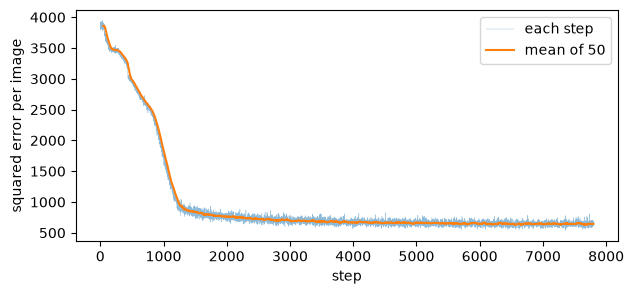

In [8]:
plt.figure(figsize=(7, 3))
plt.plot(losses, lw=0.3, alpha=0.5, label="each step")
window = 50
plt.plot(np.arange(window - 1, len(losses)), np.convolve(losses, np.ones(window) / window, "valid"),
         label=f"mean of {window}")
plt.xlabel("step")
plt.ylabel("squared error per image")
plt.legend()
plt.show()

## 6. Generating images

Start from noise at `t = 0` and take `EULER_STEPS` Euler steps along the predicted velocity,
`z += v(z, t) * dt`, with the averaged weights. `predict` runs the network without keeping
anything for a backward pass. The update is written in place (`v *= dt; z += v`), which saves
two temporary matrices per step.

After 20 epochs the images have the colours and rough layout of CIFAR-10 scenes but are blurry;
they sharpen with longer training (section 8).

128 images in 0.5 s (100 steps)


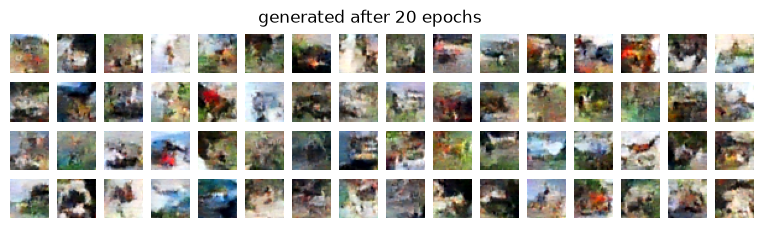

In [9]:
def generate(steps=EULER_STEPS, keep_every=None):
    z = jz.randn(BATCH, 3 * 32 * 32, device=device)
    snapshots = [z.numpy()]
    for s in range(steps):
        t = jz.ones(BATCH, 1, device=device) * (s / steps)
        v = net(z, t, train=False)
        v *= 1 / steps
        z += v
        if keep_every and (s + 1) % keep_every == 0:
            snapshots.append(z.numpy())
    return z, snapshots

ema.swap()                                  # draw with the averaged weights
start = time.perf_counter()
samples, snapshots = generate(keep_every=EULER_STEPS // 4)
samples.numpy()                             # waits for the GPU
sampling_seconds = time.perf_counter() - start
ema.swap()                                  # back to the trained weights
print(f"{BATCH} images in {sampling_seconds:.1f} s ({EULER_STEPS} steps)")

show_images(samples[:64], title=f"generated after {EPOCHS} epochs")

How noise turns into images: eight samples at `t` = 0, 0.25, 0.5, 0.75 and 1.

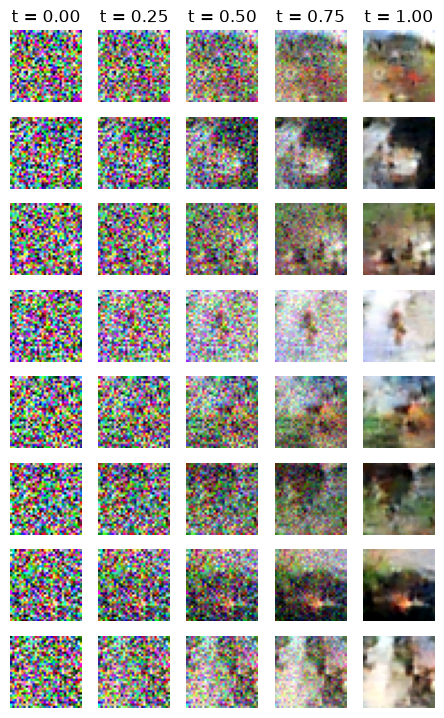

In [10]:
fig, axes = plt.subplots(8, len(snapshots), figsize=(len(snapshots) * 1.1, 8 * 1.1))
for column, snapshot in enumerate(snapshots):
    pictures = ((snapshot[:8].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1) + 1) / 2).clip(0, 1)
    for row in range(8):
        axes[row, column].imshow(pictures[row])
        axes[row, column].axis("off")
    axes[0, column].set_title(f"t = {column / (len(snapshots) - 1):.2f}")
plt.show()

## 7. Speed: Python and C++

The same training run in C++ is `examples/demo_cnn_rectified.cu`, built with the tests and
examples (see the main README). Its settings are environment variables; one epoch, with few
images drawn at the end of the epoch:

```
RF_EPOCHS=1 RF_FID_SAMPLES=128 ./demo_cnn_rectified
```

It prints the time of the epoch's training as `Epoch 1 done. ... elapsed=`. This notebook's
time per epoch is below; measured results for both are in the table that follows.

In [11]:
print(f"Python, {jz.backend()}: {np.mean(epoch_seconds):.1f} s per epoch of training "
      f"({1000 * np.mean(epoch_seconds) / steps_per_epoch:.0f} ms per step), "
      f"{sampling_seconds:.1f} s to draw {BATCH} images")

Python, cuda: 7.6 s per epoch of training (20 ms per step), 0.5 s to draw 128 images


Measured with `WIDTH = 64` and `BATCH = 128`, both versions reading the loss every step. Training
is the time per step from step 51 to the end of the first epoch (C++) or from step 11 on (Python);
generating is one batch of 128 images with 100 Euler steps (for C++, from its total time).

| GPU | C++, per training step | Python, per training step | one epoch (390 steps) | generating 128 images, C++ / Python |
|---|---|---|---|---|
| NVIDIA RTX 4090 (CUDA) | 18.6 ms | 19-20 ms | 7.5 s | about 0.5 s / 0.5 s |
| AMD gfx1151 (ROCm, Windows) | 690-706 ms | 638-680 ms | 4.5 min | about 21 s / 19 s |
| Apple M2 (Metal) | 2,020 ms | 1,975 ms | 13 min | about 43 s / 43 s |

The two run at the same speed. Nearly all the time is spent in the convolution layers, which
are the same C++ code either way; what Python adds (calling the pieces, joining the skip
connections, copying each piece's input for its backward pass) is at most a few percent of a step.

## 8. Next steps

* **Train longer.** The C++ demo's notes give FID-10k (lower is better) of 41 after 200 epochs
  and 29 after 1,000 for `WIDTH = 64`; 22 for `WIDTH = 128` after 1,000 epochs.
* **Keep the weights.** `net.pieces[k].state_dict()` gives each piece's parameters as numpy
  arrays, and `jz.save_checkpoint(piece, path)` writes a piece with its optimizer state.
* **Sample better.** Heun's method (two network calls per step) gives better images than Euler's
  for the same number of calls when the steps are few.